# GIAI ĐOẠN 2 & 3: LÀM SẠCH NÂNG CAO, TẠO ĐẶC TRƯNG & EDA ĐA BIẾN
## (FEATURE ENGINEERING & POST-PROCESSING MULTIVARIATE EDA)



![Quy trình tổng thể](../figures/00_quy_trinh_tong_the.png)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import re

# Cấu hình thẩm mỹ trực quan hóa chuẩn xuất bản
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.dpi'] = 120

os.makedirs('../figures', exist_ok=True)
os.makedirs('../datas', exist_ok=True)
print("Môi trường sẵn sàng cho Pha Feature Engineering & Multivariate EDA!")

Môi trường sẵn sàng cho Pha Feature Engineering & Multivariate EDA!


### 1. Nạp Dữ liệu & Khởi tạo Tập dữ liệu Tiền xử lý


In [2]:
data_path = '../datas/laptop_price - dataset.csv'
df_raw = pd.read_csv(data_path)
df_clean = df_raw.drop_duplicates().reset_index(drop=True)

# 1. Loại bỏ mẫu ngoại lai duy nhất (Samsung ARM Cortex / GPU Mali)
df_clean = df_clean[df_clean['CPU_Company'] != 'Samsung'].reset_index(drop=True)

# 2. Loại bỏ điểm ngoại lai cực đoan đơn lẻ về dung lượng RAM (Asus ROG G701VO với RAM = 64GB, n=1)
df_clean = df_clean[df_clean['RAM (GB)'] != 64].reset_index(drop=True)

print(f"Kích thước dữ liệu chuẩn hóa (đã loại bỏ 2 điểm ngoại lai cực đoan đơn lẻ: Samsung ARM & RAM 64GB): {df_clean.shape[0]:,} dòng, {df_clean.shape[1]} cột.")

Kích thước dữ liệu chuẩn hóa (đã loại bỏ 2 điểm ngoại lai cực đoan đơn lẻ: Samsung ARM & RAM 64GB): 1,273 dòng, 15 cột.


### 2. Kỹ thuật Tạo Đặc trưng (Feature Engineering)

#### 2.1 Bóc tách Thông số Màn hình: `Touchscreen`, `IPS_Panel` và Mật độ điểm ảnh `PPI`
- Cảm ứng: `Touchscreen` (1 nếu có cảm ứng, 0 nếu không).
- Tấm nền: `IPS_Panel` (1 nếu là IPS Panel, 0 nếu màn hình thường).
- Mật độ điểm ảnh: $\text{PPI} = \frac{\sqrt{\text{Resolution\_X}^2 + \text{Resolution\_Y}^2}}{\text{Inches}}$.

In [3]:
def extract_screen_features(df):
    df = df.copy()
    
    # 1. Cảm ứng (Touchscreen)
    df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if 'touchscreen' in str(x).lower() else 0)
    
    # 2. Tấm nền IPS (IPS_Panel)
    df['IPS_Panel'] = df['ScreenResolution'].apply(lambda x: 1 if 'ips panel' in str(x).lower() else 0)
    
    # 3. Trích xuất độ phân giải X, Y
    def get_resolution(text):
        match = re.search(r'(\d{3,4})\s*x\s*(\d{3,4})', str(text))
        if match:
            return int(match.group(1)), int(match.group(2))
        return np.nan, np.nan
    
    res = df['ScreenResolution'].apply(get_resolution)
    df['Resolution_X'] = [r[0] for r in res]
    df['Resolution_Y'] = [r[1] for r in res]
    
    # 4. Mật độ điểm ảnh PPI
    df['PPI'] = np.sqrt(df['Resolution_X']**2 + df['Resolution_Y']**2) / df['Inches']
    df['PPI'] = df['PPI'].round(2)
    
    return df

df_clean = extract_screen_features(df_clean)
print("Nghiệm thu đặc trưng màn hình:")
print(df_clean[['ScreenResolution', 'Touchscreen', 'IPS_Panel', 'Resolution_X', 'Resolution_Y', 'PPI']].head())

Nghiệm thu đặc trưng màn hình:
                     ScreenResolution  Touchscreen  IPS_Panel  Resolution_X  \
0  IPS Panel Retina Display 2560x1600            0          1          2560   
1                            1440x900            0          0          1440   
2                   Full HD 1920x1080            0          0          1920   
3  IPS Panel Retina Display 2880x1800            0          1          2880   
4  IPS Panel Retina Display 2560x1600            0          1          2560   

   Resolution_Y     PPI  
0          1600  226.98  
1           900  127.68  
2          1080  141.21  
3          1800  220.53  
4          1600  226.98  


#### 2.2 Phân rã Ổ cứng Lưu trữ: `SSD_GB`, `HDD_GB`, `Flash_Storage_GB`, `Hybrid_GB` và `Has_SSD`
- Bóc tách chi tiết dung lượng từng loại ổ cứng quy đổi về GB (1TB = 1024GB).
- Tạo biến cờ `Has_SSD` (1 nếu có ổ SSD, 0 nếu chỉ có HDD/Flash).

In [4]:
def parse_storage(memory_str):
    ssd, hdd, flash, hybrid = 0, 0, 0, 0
    parts = str(memory_str).split('+')
    
    for p in parts:
        p = p.strip()
        num_match = re.search(r'(\d+(\.\d+)?)', p)
        if not num_match:
            continue
        val = float(num_match.group(1))
        
        # Quy đổi TB -> GB
        if 'tb' in p.lower():
            val = val * 1024
            
        p_lower = p.lower()
        if 'ssd' in p_lower:
            ssd += val
        elif 'hdd' in p_lower:
            hdd += val
        elif 'flash' in p_lower:
            flash += val
        elif 'hybrid' in p_lower:
            hybrid += val
            
    return pd.Series([ssd, hdd, flash, hybrid], index=['SSD_GB', 'HDD_GB', 'Flash_Storage_GB', 'Hybrid_GB'])

storage_df = df_clean['Memory'].apply(parse_storage)
df_clean = pd.concat([df_clean, storage_df], axis=1)

df_clean['Total_Storage_GB'] = df_clean['SSD_GB'] + df_clean['HDD_GB'] + df_clean['Flash_Storage_GB'] + df_clean['Hybrid_GB']
df_clean['Has_SSD'] = (df_clean['SSD_GB'] > 0).astype(int)

print("Nghiệm thu đặc trưng ổ cứng:")
print(df_clean[['Memory', 'SSD_GB', 'HDD_GB', 'Total_Storage_GB', 'Has_SSD']].head())

Nghiệm thu đặc trưng ổ cứng:
                Memory  SSD_GB  HDD_GB  Total_Storage_GB  Has_SSD
0            128GB SSD   128.0     0.0             128.0        1
1  128GB Flash Storage     0.0     0.0             128.0        0
2            256GB SSD   256.0     0.0             256.0        1
3            512GB SSD   512.0     0.0             512.0        1
4            256GB SSD   256.0     0.0             256.0        1


#### 2.3 Phân cấp Vi xử lý (`CPU_Tier`), Đồ họa (`GPU_Dedicated`) & Hệ điều hành (`OpSys_Group`)
> **Cải tiến quan trọng:**
> - **Khắc phục triệt để lỗi gom nhóm:** Tách riêng dòng máy trạm cao cấp **`Intel Xeon`** (giá từ €1.993 đến €4.899) và dòng mỏng nhẹ cao cấp **`Intel Core M`** ra khỏi nhóm vi xử lý giá rẻ **`Intel Entry-Level`** (gồm Celeron, Pentium, Atom giá từ €174 đến €775).
> - Phân loại card đồ họa: `GPU_Dedicated` (1: Card rời Nvidia/AMD vs 0: Card Onboard).
> - Phân loại 9 hệ điều hành thành 5 nhóm `OpSys_Group` rõ ràng (Windows, macOS, Linux, No OS, Chrome OS) 

In [5]:
# 1. Phân cấp CPU chuẩn xác
def categorize_cpu(row):
    cpu_comp = str(row['CPU_Company']).strip()
    cpu_type = str(row['CPU_Type']).strip()
    
    # Máy trạm chuyên nghiệp Workstation
    if 'Xeon' in cpu_type:
        return 'Intel Xeon'
    # Các phân khúc Intel Core i phổ biến
    elif 'Core i7' in cpu_type:
        return 'Intel Core i7'
    elif 'Core i5' in cpu_type:
        return 'Intel Core i5'
    elif 'Core i3' in cpu_type:
        return 'Intel Core i3'
    # Dòng chip siêu tiết kiệm điện cho Ultrabook/MacBook mỏng nhẹ
    elif 'Core M' in cpu_type:
        return 'Intel Core M'
    # Dòng vi xử lý giá rẻ bình dân
    elif any(b in cpu_type for b in ['Celeron', 'Pentium', 'Atom']):
        return 'Intel Entry-Level'
    elif cpu_comp == 'Intel':
        return 'Intel Entry-Level'
    # Dòng vi xử lý AMD
    else:
        return 'AMD Processor'

df_clean['CPU_Tier'] = df_clean.apply(categorize_cpu, axis=1)

# 2. Phân loại GPU (Dedicated vs Integrated)
def categorize_gpu(row):
    gpu_comp = str(row['GPU_Company']).strip()
    gpu_type = str(row['GPU_Type']).strip()
    if gpu_comp == 'Nvidia':
        return 'Nvidia', 1
    elif gpu_comp == 'AMD':
        if any(x in gpu_type for x in ['RX', 'Pro', 'FirePro']) or 'Radeon R' in gpu_type or 'Radeon 5' in gpu_type:
            return 'AMD (Dedicated)', 1
        return 'AMD (Integrated)', 0
    else:
        return 'Intel (Integrated)', 0

gpu_info = pd.DataFrame(
    df_clean.apply(categorize_gpu, axis=1).tolist(),
    columns=['GPU_Brand_Cat', 'GPU_Dedicated'],
    index=df_clean.index
)
df_clean = pd.concat([df_clean, gpu_info], axis=1)

# 3. Phân loại Hệ điều hành chuẩn xác (Windows, macOS, Linux, No OS, Chrome OS)
def categorize_opsys(opsys):
    opsys = str(opsys).strip()
    if 'Windows' in opsys:
        return 'Windows'
    elif 'No OS' in opsys:
        return 'No OS'
    elif 'Linux' in opsys:
        return 'Linux'
    elif 'mac' in opsys.lower():
        return 'macOS'
    else:
        return 'Chrome OS'

df_clean['OpSys_Group'] = df_clean['OpSys'].apply(categorize_opsys)

print("BẢNG PHÂN BỐ PHÂN CẤP CPU (CPU_Tier) SAU KHI CHUẨN HÓA:")
display(df_clean.groupby('CPU_Tier')['Price (Euro)'].agg(['count', 'median', 'mean', 'min', 'max']).sort_values('median', ascending=False))

BẢNG PHÂN BỐ PHÂN CẤP CPU (CPU_Tier) SAU KHI CHUẨN HÓA:


,count,median,mean,min,max
CPU_Tier,,,,,
Intel Xeon,4,3722.0,3584.000000,1993.0,4899.00
Intel Core i7,514,1481.5,1607.680875,579.0,6099.00
Intel Core M,17,1279.0,1394.258824,603.0,3100.00
Intel Core i5,423,955.0,1015.015248,393.9,2330.00
Intel Core i3,134,499.0,542.859179,339.0,1166.97
AMD Processor,60,469.0,560.993833,199.0,2199.00
Intel Entry-Level,121,329.0,349.677438,174.0,775.00


#### 2.4 Trực quan hóa  Tần suất các Đặc trưng Công nghệ Mới
- Kiểm tra trực quan số lượng và tỷ lệ phân bố của toàn bộ các đặc trưng vừa bóc tách.

C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1033004569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y=col, order=order, ax=axes[i], palette='crest')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1033004569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y=col, order=order, ax=axes[i], palette='crest')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1033004569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y=col, order=order, ax=axes[i], palette='crest')


C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1033004569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y=col, order=order, ax=axes[i], palette='crest')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1033004569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y=col, order=order, ax=axes[i], palette='crest')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1033004569.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, y=col, order=order, ax=axes[i], palette='crest')


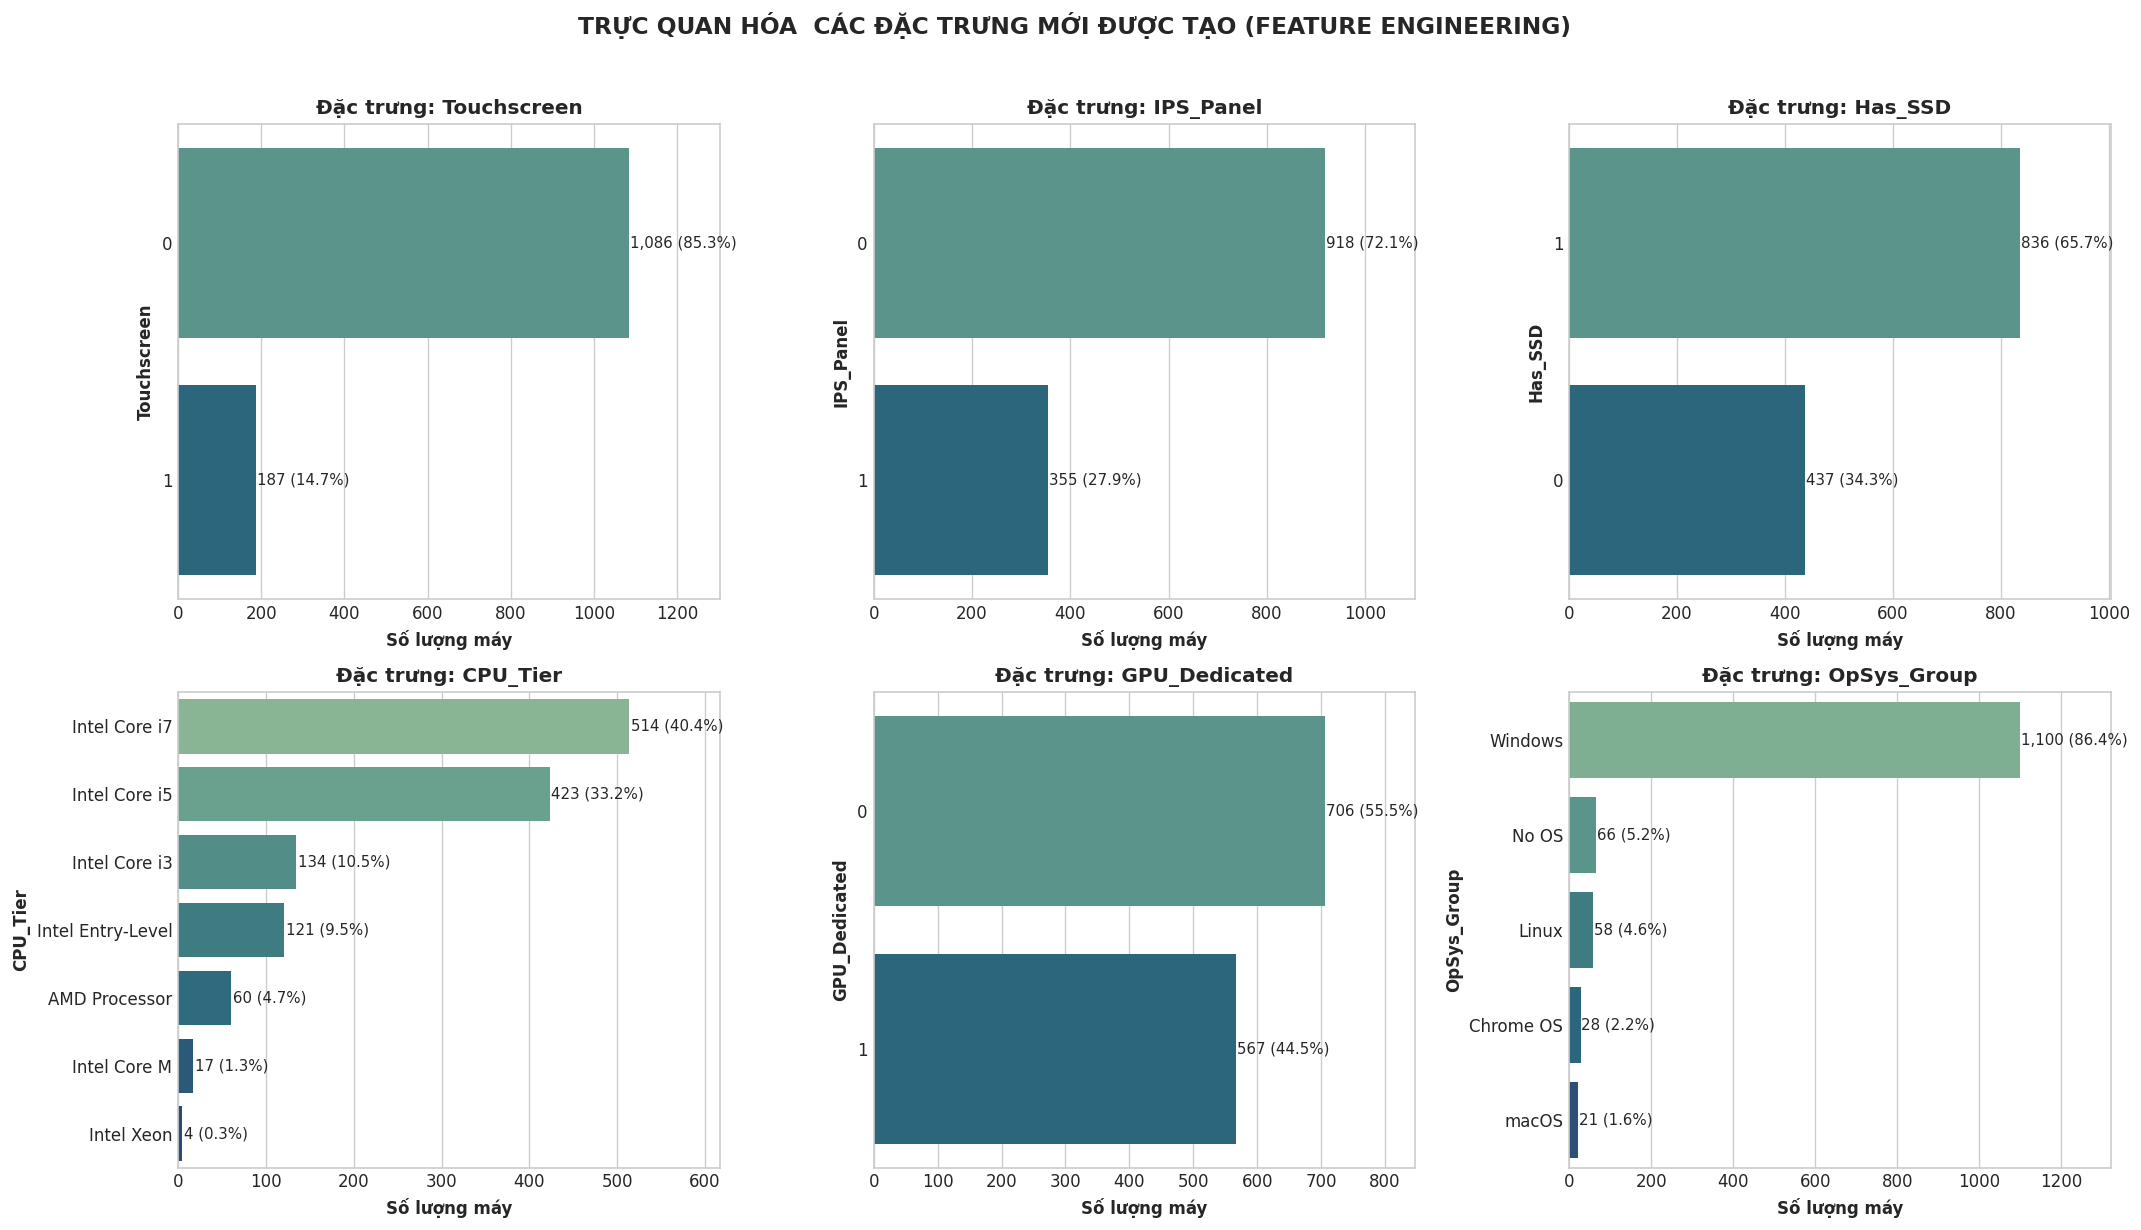

In [6]:
new_eng_cols = ['Touchscreen', 'IPS_Panel', 'Has_SSD', 'CPU_Tier', 'GPU_Dedicated', 'OpSys_Group']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(new_eng_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, y=col, order=order, ax=axes[i], palette='crest')
    axes[i].set_title(f'Đặc trưng: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Số lượng máy', fontsize=10)
    axes[i].set_ylabel(col, fontsize=10)
    
    for p in axes[i].patches:
        w = p.get_width()
        pct = w / len(df_clean) * 100
        axes[i].annotate(f'{int(w):,} ({pct:.1f}%)', (w + 2, p.get_y() + p.get_height() / 2),
                         ha='left', va='center', fontsize=9)
    axes[i].set_xlim(0, max(df_clean[col].value_counts()) * 1.2)

plt.suptitle('TRỰC QUAN HÓA  CÁC ĐẶC TRƯNG MỚI ĐƯỢC TẠO (FEATURE ENGINEERING)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/fig_06_new_features_countplot.png', dpi=300, bbox_inches='tight')
plt.show()

#### 2.5 Đóng gói Hàm Master Pipeline `engineer_laptop_features(df)`
- Hàm tái sử dụng cho các dữ liệu mới hoặc phục vụ triển khai suy luận (Inference Pipeline).

In [7]:
def engineer_laptop_features(df_input):
    df = df_input.copy()
    df = extract_screen_features(df)
    
    storage_df = df['Memory'].apply(parse_storage)
    df = pd.concat([df, storage_df], axis=1)
    df['Total_Storage_GB'] = df['SSD_GB'] + df['HDD_GB'] + df['Flash_Storage_GB'] + df['Hybrid_GB']
    df['Has_SSD'] = (df['SSD_GB'] > 0).astype(int)
    
    df['CPU_Tier'] = df.apply(categorize_cpu, axis=1)
    
    gpu_info = pd.DataFrame(
        df.apply(categorize_gpu, axis=1).tolist(),
        columns=['GPU_Brand_Cat', 'GPU_Dedicated'],
        index=df.index
    )
    df = pd.concat([df, gpu_info], axis=1)
    df['OpSys_Group'] = df['OpSys'].apply(categorize_opsys)
    
    return df

print("Hàm Master Pipeline `engineer_laptop_features(df)` đã được đóng gói thành công!")

Hàm Master Pipeline `engineer_laptop_features(df)` đã được đóng gói thành công!


### 3. Khám phá Dữ liệu Đa biến Hậu kỳ (Post-Processing EDA)

#### 3.1 Chuẩn hóa Biến mục tiêu bằng Log-transform (`np.log1p`)
- Biến mục tiêu `Price (Euro)` bị lệch phải ($Skew = 1.511$).
- Áp dụng $\text{log\_price} = \ln(\text{Price} + 1)$ để đưa về phân phối tiệm cận đối xứng quanh 0.

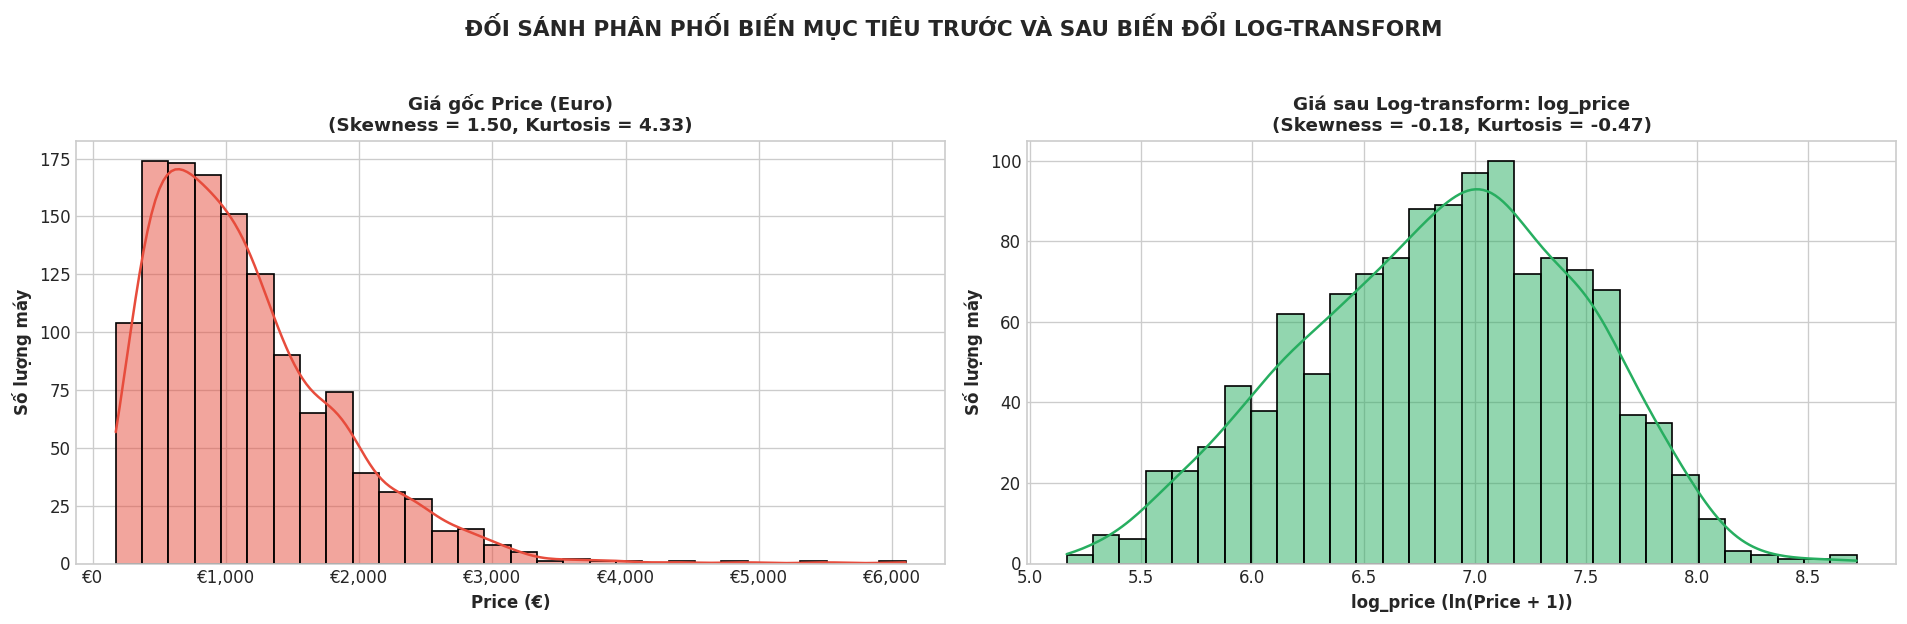

Độ lệch Skewness giảm mạnh từ 1.495 về -0.182 (đối xứng tiệm cận chuẩn)!
Độ nhọn Kurtosis giảm từ 4.325 về -0.469!


In [8]:
df_clean['log_price'] = np.log1p(df_clean['Price (Euro)'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Trước khi lấy log
skew_orig = df_clean['Price (Euro)'].skew()
kurt_orig = df_clean['Price (Euro)'].kurtosis()
sns.histplot(df_clean['Price (Euro)'], kde=True, ax=axes[0], color='#e74c3c', bins=30)
axes[0].set_title(f'Giá gốc Price (Euro)\n(Skewness = {skew_orig:.2f}, Kurtosis = {kurt_orig:.2f})', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Price (€)')
axes[0].set_ylabel('Số lượng máy')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# 2. Sau khi lấy log
skew_log = df_clean['log_price'].skew()
kurt_log = df_clean['log_price'].kurtosis()
sns.histplot(df_clean['log_price'], kde=True, ax=axes[1], color='#27ae60', bins=30)
axes[1].set_title(f'Giá sau Log-transform: log_price\n(Skewness = {skew_log:.2f}, Kurtosis = {kurt_log:.2f})', fontsize=11, fontweight='bold')
axes[1].set_xlabel('log_price (ln(Price + 1))')
axes[1].set_ylabel('Số lượng máy')

plt.suptitle('ĐỐI SÁNH PHÂN PHỐI BIẾN MỤC TIÊU TRƯỚC VÀ SAU BIẾN ĐỔI LOG-TRANSFORM', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('../figures/fig_07_log_price_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Độ lệch Skewness giảm mạnh từ {skew_orig:.3f} về {skew_log:.3f} (đối xứng tiệm cận chuẩn)!")
print(f"Độ nhọn Kurtosis giảm từ {kurt_orig:.3f} về {kurt_log:.3f}!")

#### 3.2 Phân tích Giá bán theo Phân khúc Kiểu dáng (`TypeName`) và Hãng sản xuất (`Company`)

C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\2741549189.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='Price (Euro)', y='TypeName', order=type_order, ax=axes[0], palette='Blues_r', errorbar='se')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\2741549189.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean[df_clean['Company'].isin(top_companies)], x='Price (Euro)', y='Company', order=comp_order, ax=axes[1], palette='Greens_r', errorbar='se')


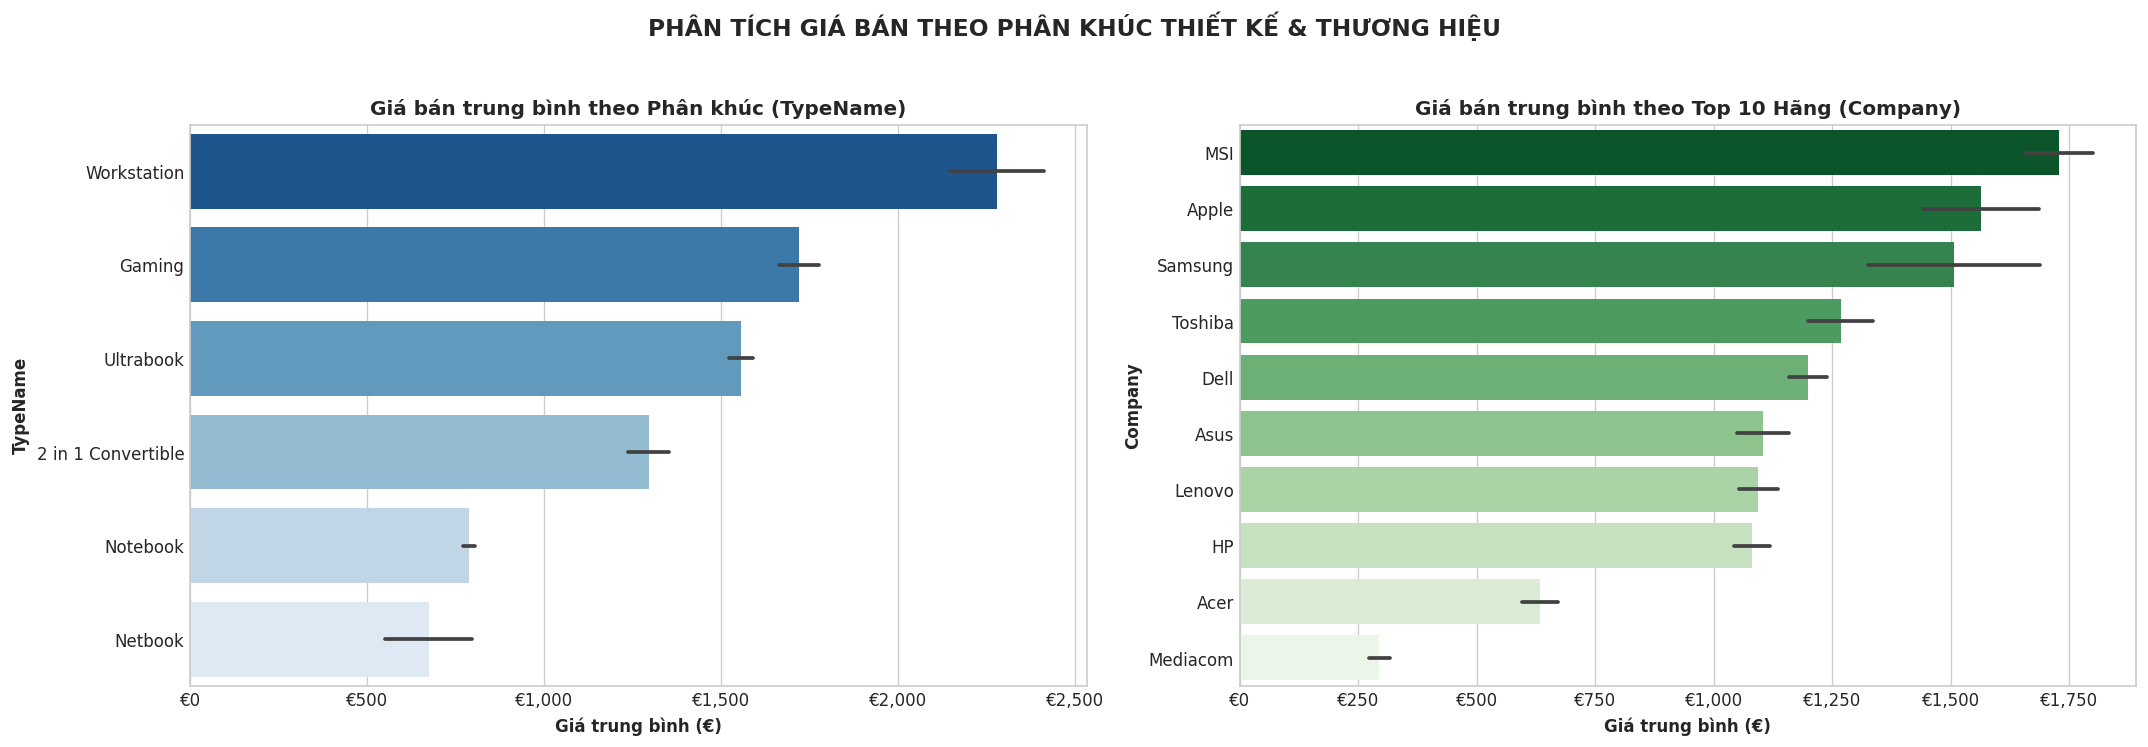

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Giá theo TypeName
type_order = df_clean.groupby('TypeName')['Price (Euro)'].mean().sort_values(ascending=False).index
sns.barplot(data=df_clean, x='Price (Euro)', y='TypeName', order=type_order, ax=axes[0], palette='Blues_r', errorbar='se')
axes[0].set_title('Giá bán trung bình theo Phân khúc (TypeName)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Giá trung bình (€)')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# 2. Giá theo Top 10 Hãng sản xuất phổ biến
top_companies = df_clean['Company'].value_counts().head(10).index
comp_order = df_clean[df_clean['Company'].isin(top_companies)].groupby('Company')['Price (Euro)'].mean().sort_values(ascending=False).index
sns.barplot(data=df_clean[df_clean['Company'].isin(top_companies)], x='Price (Euro)', y='Company', order=comp_order, ax=axes[1], palette='Greens_r', errorbar='se')
axes[1].set_title('Giá bán trung bình theo Top 10 Hãng (Company)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Giá trung bình (€)')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

plt.suptitle('PHÂN TÍCH GIÁ BÁN THEO PHÂN KHÚC THIẾT KẾ & THƯƠNG HIỆU', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('../figures/fig_08_price_by_type_and_company.png', dpi=300, bbox_inches='tight')
plt.show()

#### 3.3 Phân tích Tác động của Cấu hình Phần cứng (RAM, CPU Tier, GPU, SSD) đến Giá bán
> **Chuẩn hóa trực quan:**
> - Thứ tự trục X của `CPU_Tier` được sắp xếp theo đúng **bậc thang giá trị thực tế**:  
>   `Intel Xeon` ➔ `Intel Core i7` ➔ `Intel Core M` ➔ `Intel Core i5` ➔ `Intel Core i3` ➔ `AMD Processor` ➔ `Intel Entry-Level`.
> - Loại bỏ hoàn toàn sự pha trộn bất thường của các máy trạm Xeon trong phân khúc giá rẻ.

C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\341804206.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='RAM (GB)', y='Price (Euro)', ax=axes[0, 0], palette='Purples')


C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\341804206.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='CPU_Tier', y='Price (Euro)', order=cpu_available_order, ax=axes[0, 1], palette='Oranges_r')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\341804206.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='GPU_Dedicated', y='Price (Euro)', ax=axes[1, 0], palette=['#95a5a6', '#e74c3c'])


C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\341804206.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 0].set_xticklabels(['Card Onboard', 'Card Rời (Dedicated)'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\341804206.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Has_SSD', y='Price (Euro)', ax=axes[1, 1], palette=['#95a5a6', '#2ecc71'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\341804206.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(['Không có SSD (HDD/Flash)', 'Có trang bị SSD'])


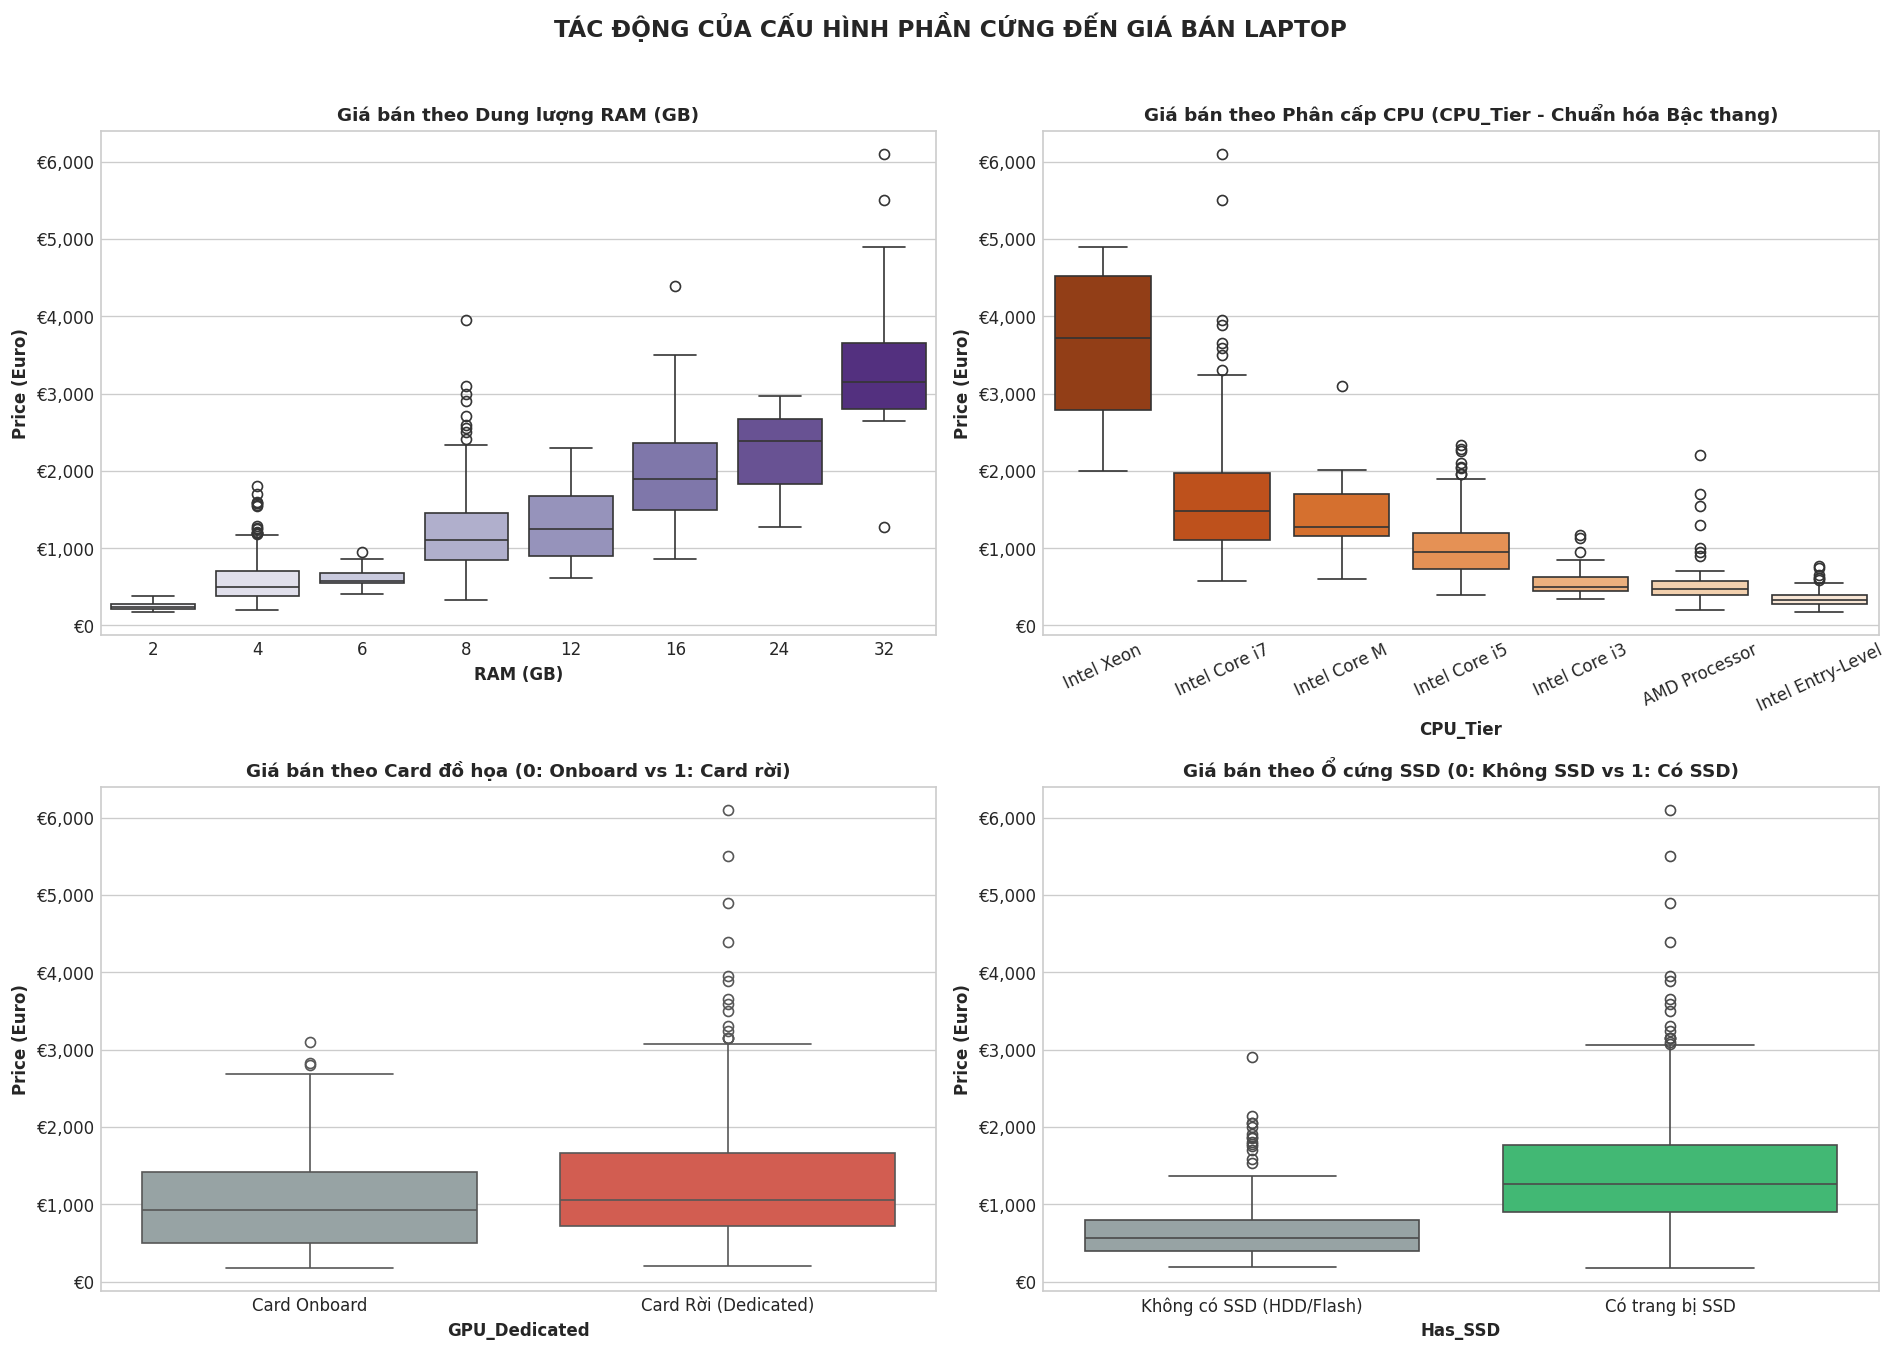

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. RAM vs Price
sns.boxplot(data=df_clean, x='RAM (GB)', y='Price (Euro)', ax=axes[0, 0], palette='Purples')
axes[0, 0].set_title('Giá bán theo Dung lượng RAM (GB)', fontsize=11, fontweight='bold')
axes[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# 2. CPU Tier vs Price (Sắp xếp theo thứ tự phân cấp giá trị chuẩn mực)
cpu_hierarchy = ['Intel Xeon', 'Intel Core i7', 'Intel Core M', 'Intel Core i5', 'Intel Core i3', 'AMD Processor', 'Intel Entry-Level']
cpu_available_order = [c for c in cpu_hierarchy if c in df_clean['CPU_Tier'].unique()]

sns.boxplot(data=df_clean, x='CPU_Tier', y='Price (Euro)', order=cpu_available_order, ax=axes[0, 1], palette='Oranges_r')
axes[0, 1].set_title('Giá bán theo Phân cấp CPU (CPU_Tier - Chuẩn hóa Bậc thang)', fontsize=11, fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=25)
axes[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# 3. GPU Dedicated vs Price
sns.boxplot(data=df_clean, x='GPU_Dedicated', y='Price (Euro)', ax=axes[1, 0], palette=['#95a5a6', '#e74c3c'])
axes[1, 0].set_title('Giá bán theo Card đồ họa (0: Onboard vs 1: Card rời)', fontsize=11, fontweight='bold')
axes[1, 0].set_xticklabels(['Card Onboard', 'Card Rời (Dedicated)'])
axes[1, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# 4. Has SSD vs Price
sns.boxplot(data=df_clean, x='Has_SSD', y='Price (Euro)', ax=axes[1, 1], palette=['#95a5a6', '#2ecc71'])
axes[1, 1].set_title('Giá bán theo Ổ cứng SSD (0: Không SSD vs 1: Có SSD)', fontsize=11, fontweight='bold')
axes[1, 1].set_xticklabels(['Không có SSD (HDD/Flash)', 'Có trang bị SSD'])
axes[1, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

plt.suptitle('TÁC ĐỘNG CỦA CẤU HÌNH PHẦN CỨNG ĐẾN GIÁ BÁN LAPTOP ', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/fig_09_hardware_vs_price.png', dpi=300, bbox_inches='tight')
plt.show()

#### 3.4 Phân tích Màn hình & Chất lượng hiển thị tác động đến Giá bán

C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1115331194.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Touchscreen', y='Price (Euro)', ax=axes[0], palette=['#3498db', '#9b59b6'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1115331194.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Thường', 'Cảm ứng'])
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\1115331194.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='IPS_Panel', y='Price (Euro)', ax=axes[1], palette=['#3498db', '#e67e22'])
C:\Users\Admin\AppData\Local\Temp\ipykern

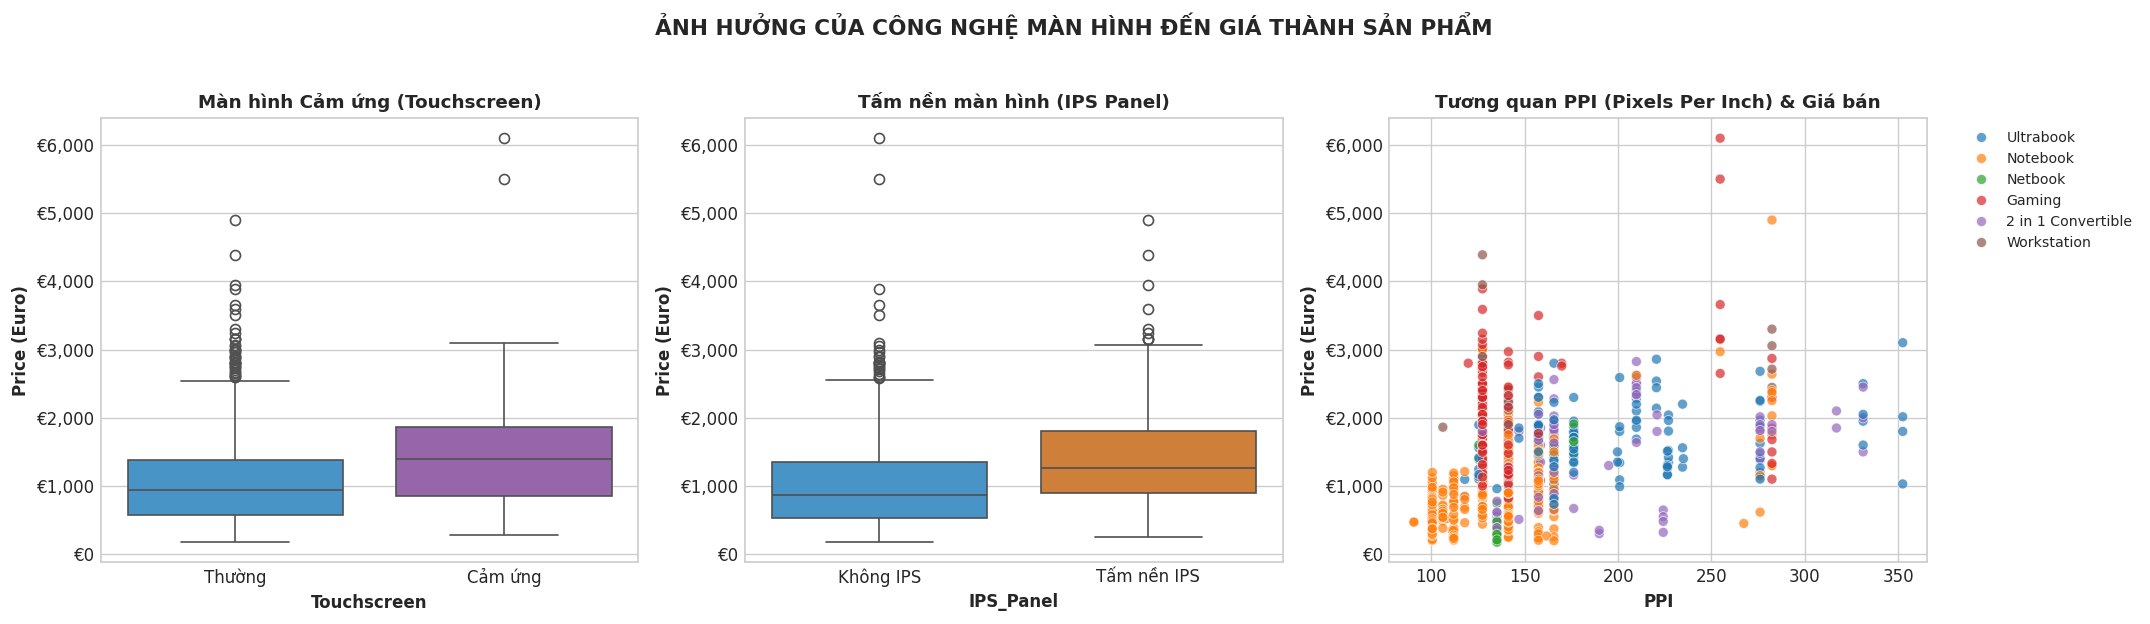

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Touchscreen vs Price
sns.boxplot(data=df_clean, x='Touchscreen', y='Price (Euro)', ax=axes[0], palette=['#3498db', '#9b59b6'])
axes[0].set_title('Màn hình Cảm ứng (Touchscreen)', fontsize=11, fontweight='bold')
axes[0].set_xticklabels(['Thường', 'Cảm ứng'])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# 2. IPS Panel vs Price
sns.boxplot(data=df_clean, x='IPS_Panel', y='Price (Euro)', ax=axes[1], palette=['#3498db', '#e67e22'])
axes[1].set_title('Tấm nền màn hình (IPS Panel)', fontsize=11, fontweight='bold')
axes[1].set_xticklabels(['Không IPS', 'Tấm nền IPS'])
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))

# 3. Mật độ điểm ảnh PPI vs Price
sns.scatterplot(data=df_clean, x='PPI', y='Price (Euro)', hue='TypeName', alpha=0.7, ax=axes[2])
axes[2].set_title('Tương quan PPI (Pixels Per Inch) & Giá bán', fontsize=11, fontweight='bold')
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))
axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8.5)

plt.suptitle('ẢNH HƯỞNG CỦA CÔNG NGHỆ MÀN HÌNH ĐẾN GIÁ THÀNH SẢN PHẨM', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('../figures/fig_10_screen_vs_price.png', dpi=300, bbox_inches='tight')
plt.show()

#### 3.5 Ma trận Tương quan Tuyến tính (Correlation Matrix & Heatmap)
- Tính toán hệ số tương quan Pearson giữa tất cả các thuộc tính định lượng sau khi đã tạo đặc trưng.

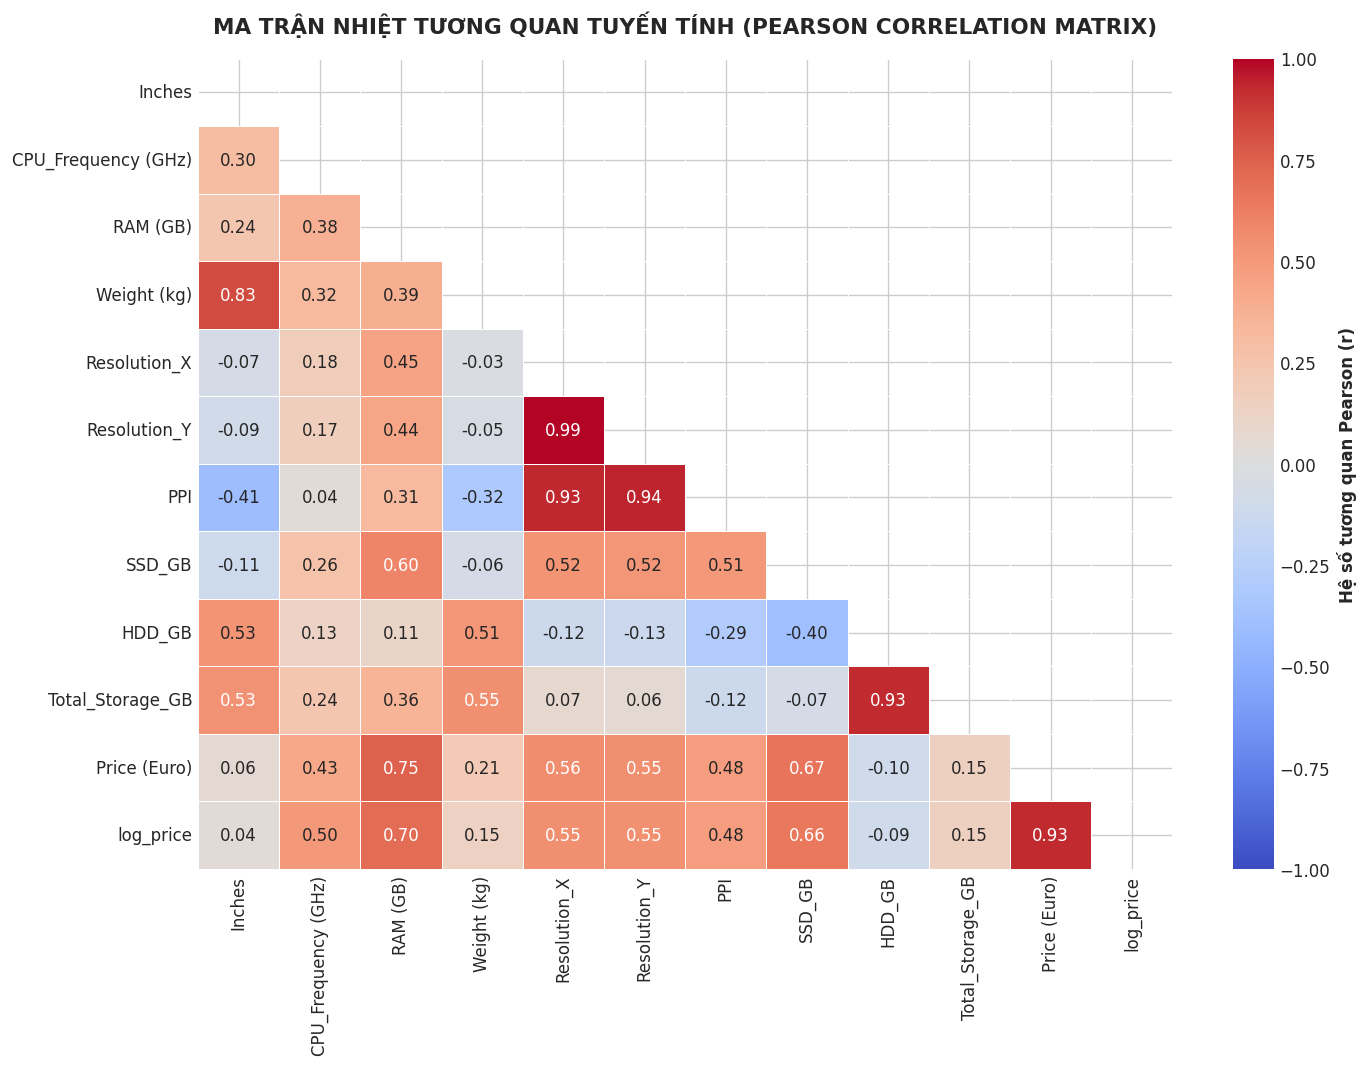

In [12]:
corr_cols = [
    'Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)',
    'Resolution_X', 'Resolution_Y', 'PPI', 'SSD_GB', 'HDD_GB', 'Total_Storage_GB',
    'Price (Euro)', 'log_price'
]

corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Hệ số tương quan Pearson (r)'})
plt.title('MA TRẬN NHIỆT TƯƠNG QUAN TUYẾN TÍNH (PEARSON CORRELATION MATRIX)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../figures/fig_11_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

#### 3.6 Đối soát Tương quan Pearson Chuyên sâu & Scatter Plot kèm Trendline
- Xếp hạng mức độ tương quan tuyến tính của các thuộc tính với biến mục tiêu `Price (Euro)` và `log_price`.

BẢNG XẾP HẠNG HỆ SỐ TƯƠNG QUAN PEARSON VỚI BIẾN MỤC TIÊU:


,Price (Euro),log_price
Price (Euro),1.000000,0.928987
log_price,0.928987,1.000000
RAM (GB),0.745725,0.695658
SSD_GB,0.665227,0.655915
Resolution_X,0.556828,0.548631
Resolution_Y,0.553873,0.546580
PPI,0.476567,0.483288
CPU_Frequency (GHz),0.429038,0.500778
Weight (kg),0.205790,0.147408
Total_Storage_GB,0.154509,0.150652


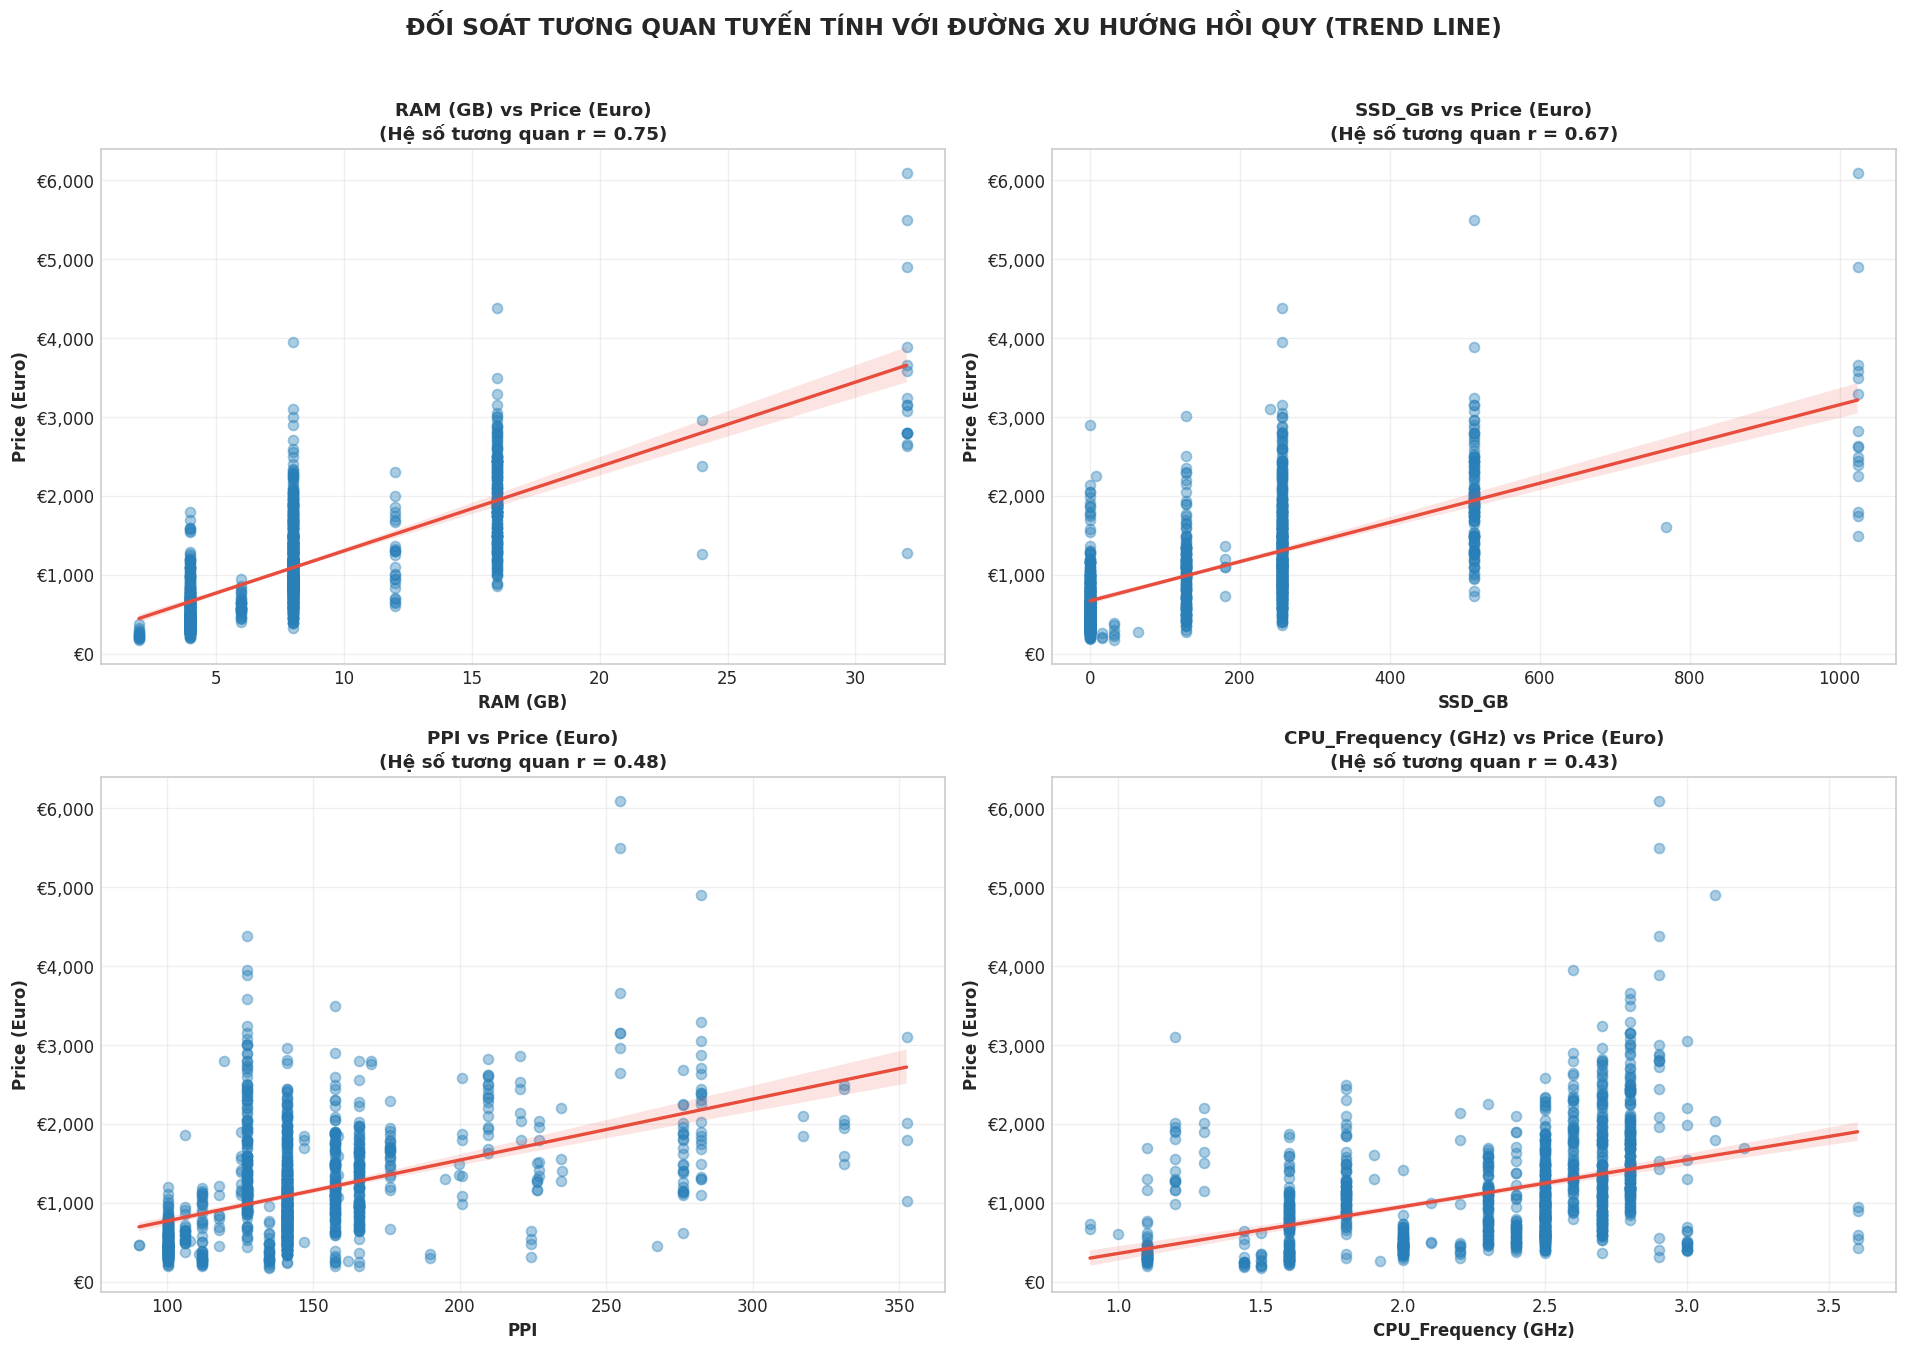

In [13]:
# Bảng xếp hạng tương quan
corr_ranking = corr_matrix[['Price (Euro)', 'log_price']].sort_values(by='Price (Euro)', ascending=False)
print("BẢNG XẾP HẠNG HỆ SỐ TƯƠNG QUAN PEARSON VỚI BIẾN MỤC TIÊU:")
display(corr_ranking)

# Lưới 4 biểu đồ tán xạ kèm đường xu hướng hồi quy (regplot)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
strong_features = ['RAM (GB)', 'SSD_GB', 'PPI', 'CPU_Frequency (GHz)']

for i, col in enumerate(strong_features):
    ax = axes[i // 2, i % 2]
    r_val = corr_matrix.loc[col, 'Price (Euro)']
    sns.regplot(data=df_clean, x=col, y='Price (Euro)', ax=ax,
                scatter_kws={'alpha': 0.4, 'color': '#2980b9'},
                line_kws={'color': '#e74c3c', 'linewidth': 2})
    ax.set_title(f'{col} vs Price (Euro)\n(Hệ số tương quan r = {r_val:.2f})', fontsize=11, fontweight='bold')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'€{x:,.0f}'))
    ax.grid(alpha=0.3)

plt.suptitle('ĐỐI SOÁT TƯƠNG QUAN TUYẾN TÍNH VỚI ĐƯỜNG XU HƯỚNG HỒI QUY (TREND LINE)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/fig_12_scatter_trendlines.png', dpi=300, bbox_inches='tight')
plt.show()

#### 3.7 Kiểm định Thống kê One-Way ANOVA (Biến Danh mục vs log_price)
- **Giả thuyết nghiên cứu:**
  - $H_0$: Kỳ vọng giá trung bình giữa các nhóm là bằng nhau.
  - $H_1$: Có ít nhất một nhóm có giá trung bình khác biệt đáng kể.

In [14]:
anova_features = ['TypeName', 'Company', 'CPU_Tier', 'OpSys_Group', 'GPU_Dedicated', 'Touchscreen', 'IPS_Panel', 'Has_SSD']
anova_results = []

for feat in anova_features:
    groups = [group['log_price'].dropna().values for _, group in df_clean.groupby(feat)]
    if len(groups) > 1:
        f_stat, p_val = stats.f_oneway(*groups)
        anova_results.append({
            'Thuộc tính kiểm định': feat,
            'Số lượng nhóm': len(groups),
            'F-Statistic': round(f_stat, 2),
            'p-value': p_val,
            'Kết luận (alpha = 0.05)': 'Có ý nghĩa thống kê (Bác bỏ H0)' if p_val < 0.05 else 'Không có ý nghĩa (Chấp nhận H0)'
        })

df_anova = pd.DataFrame(anova_results).sort_values(by='F-Statistic', ascending=False).reset_index(drop=True)
print("BẢNG KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ ONE-WAY ANOVA (VS LOG_PRICE):")
display(df_anova)

BẢNG KẾT QUẢ KIỂM ĐỊNH THỐNG KÊ ONE-WAY ANOVA (VS LOG_PRICE):


,Thuộc tính kiểm định,Số lượng nhóm,F-Statistic,p-value,Kết luận (alpha = 0.05)
0,Has_SSD,2,670.12,5.088425e-119,Có ý nghĩa thống kê (Bác bỏ H0)
1,CPU_Tier,7,371.29,7.132483e-275,Có ý nghĩa thống kê (Bác bỏ H0)
2,TypeName,6,171.33,2.475496e-139,Có ý nghĩa thống kê (Bác bỏ H0)
3,IPS_Panel,2,106.15,5.809574e-24,Có ý nghĩa thống kê (Bác bỏ H0)
4,Touchscreen,2,50.67,1.824396e-12,Có ý nghĩa thống kê (Bác bỏ H0)
5,GPU_Dedicated,2,49.88,2.681836e-12,Có ý nghĩa thống kê (Bác bỏ H0)
6,OpSys_Group,5,47.20,5.065502e-37,Có ý nghĩa thống kê (Bác bỏ H0)
7,Company,19,16.17,1.512979e-45,Có ý nghĩa thống kê (Bác bỏ H0)


#### 3.8 Trực quan hóa Phân phối log_price theo Biến Danh mục Có F-Statistic Cao

C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\2272150872.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='TypeName', y='log_price', order=type_order, ax=axes[0, 0], palette='Set2')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\2272150872.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='CPU_Tier', y='log_price', order=cpu_order, ax=axes[0, 1], palette='Pastel1')


C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\2272150872.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='OpSys_Group', y='log_price', order=available_opsys, ax=axes[1, 0], palette='Set3')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\2272150872.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='GPU_Dedicated', y='log_price', ax=axes[1, 1], palette='coolwarm')
C:\Users\Admin\AppData\Local\Temp\ipykernel_10336\2272150872.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(['Card Onboard', 'Card Rời'])


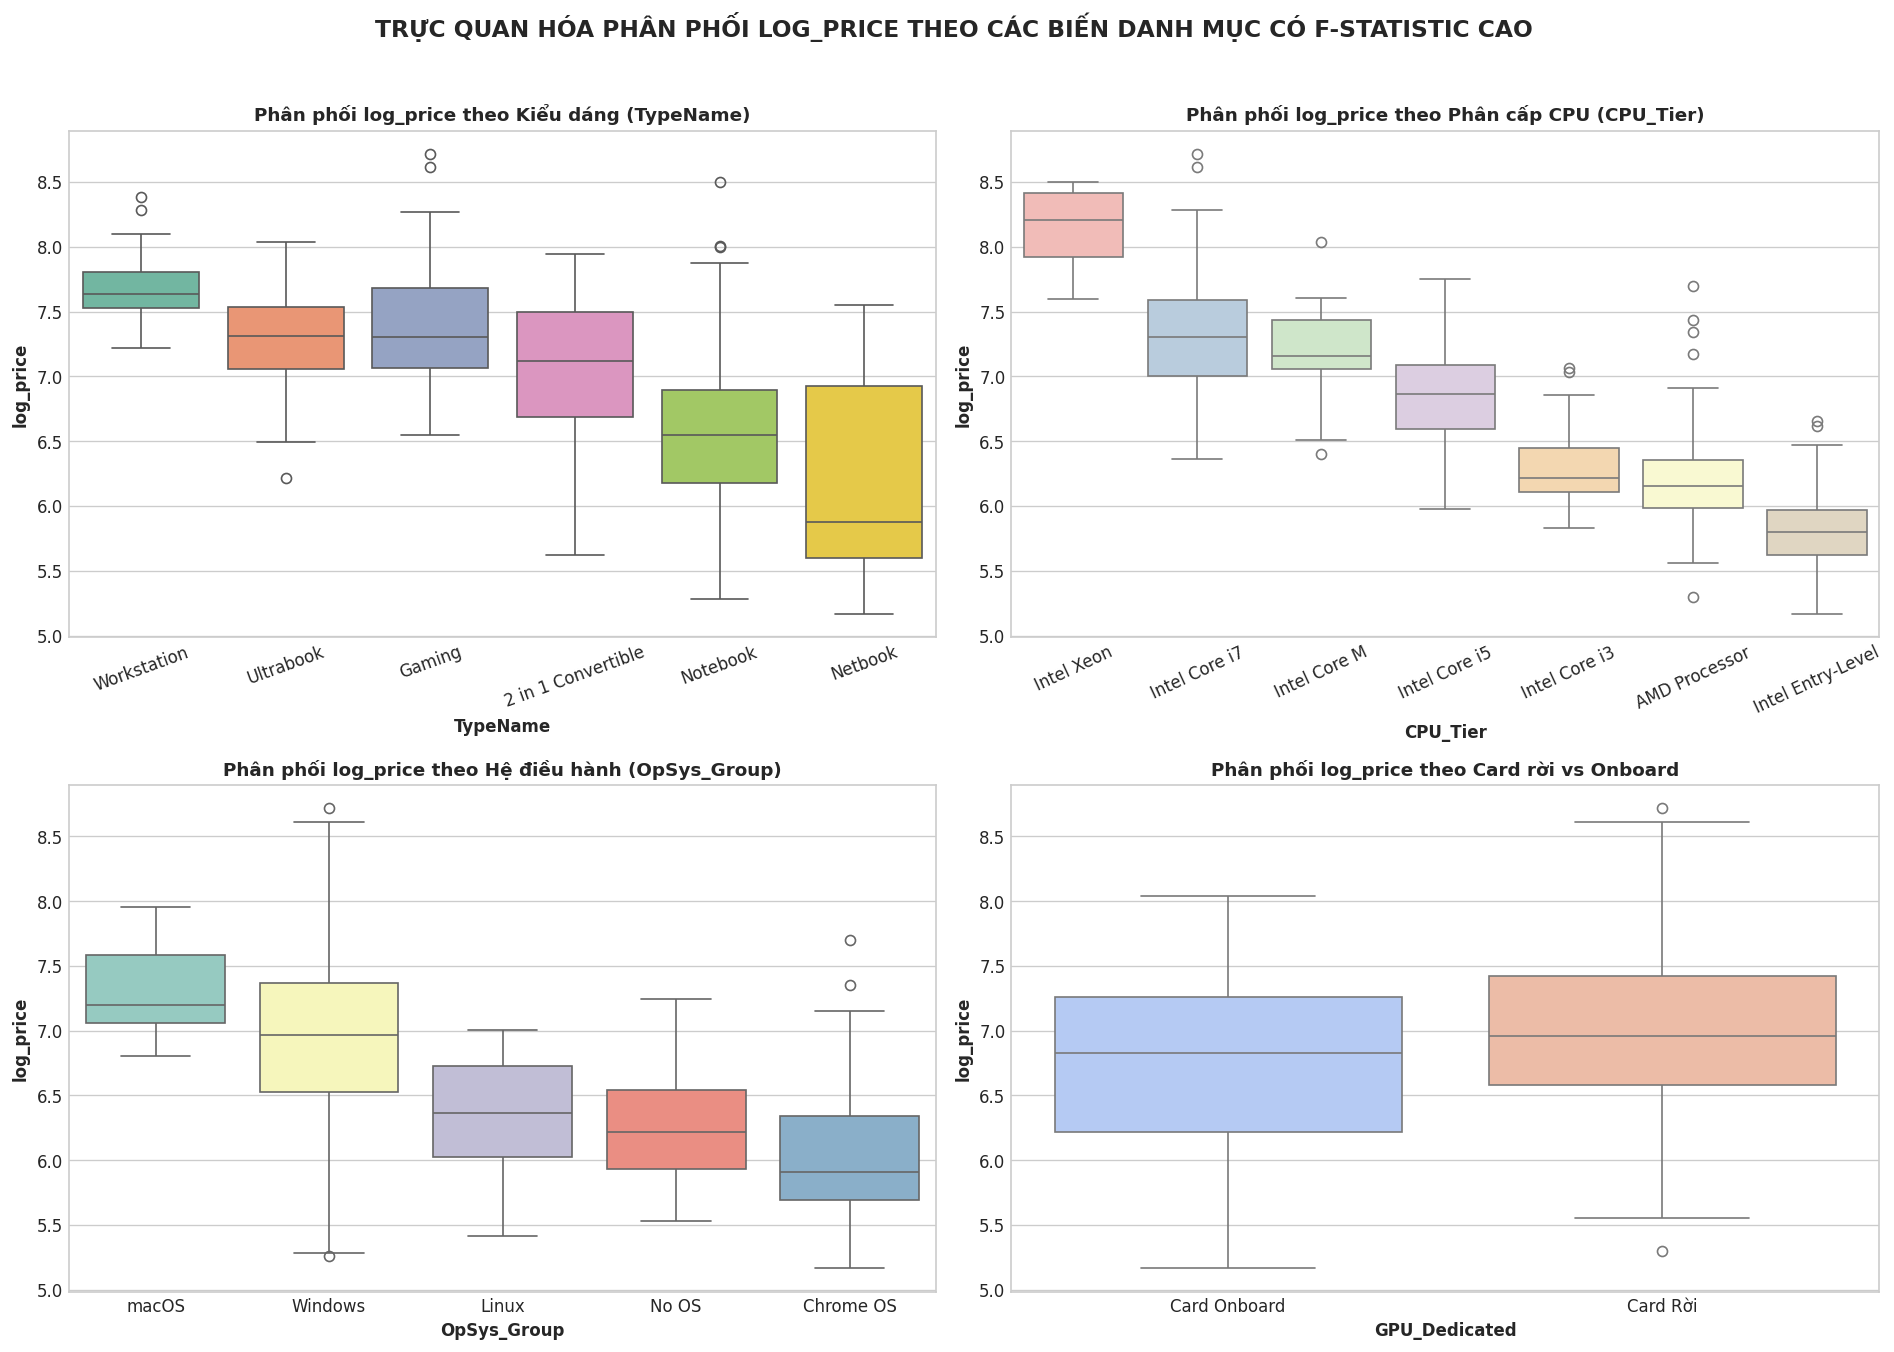

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. TypeName vs log_price
type_order = df_clean.groupby('TypeName')['log_price'].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x='TypeName', y='log_price', order=type_order, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Phân phối log_price theo Kiểu dáng (TypeName)', fontsize=11, fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=20)

# 2. CPU_Tier vs log_price
cpu_order = [c for c in cpu_hierarchy if c in df_clean['CPU_Tier'].unique()]
sns.boxplot(data=df_clean, x='CPU_Tier', y='log_price', order=cpu_order, ax=axes[0, 1], palette='Pastel1')
axes[0, 1].set_title('Phân phối log_price theo Phân cấp CPU (CPU_Tier)', fontsize=11, fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=25)

# 3. OpSys_Group vs log_price
opsys_order = ['macOS', 'Windows', 'Linux', 'No OS', 'Chrome OS']
available_opsys = [o for o in opsys_order if o in df_clean['OpSys_Group'].unique()]
sns.boxplot(data=df_clean, x='OpSys_Group', y='log_price', order=available_opsys, ax=axes[1, 0], palette='Set3')
axes[1, 0].set_title('Phân phối log_price theo Hệ điều hành (OpSys_Group)', fontsize=11, fontweight='bold')

# 4. GPU_Dedicated vs log_price
sns.boxplot(data=df_clean, x='GPU_Dedicated', y='log_price', ax=axes[1, 1], palette='coolwarm')
axes[1, 1].set_title('Phân phối log_price theo Card rời vs Onboard', fontsize=11, fontweight='bold')
axes[1, 1].set_xticklabels(['Card Onboard', 'Card Rời'])

plt.suptitle('TRỰC QUAN HÓA PHÂN PHỐI LOG_PRICE THEO CÁC BIẾN DANH MỤC CÓ F-STATISTIC CAO', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../figures/fig_13_categorical_vs_log_price_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### 4. Xuất Dữ liệu Đã Làm Sạch (Export Cleaned Data)

#### 4.1 Quyết định Phương pháp luận: Vì sao LOẠI BỎ cột `Product` và các cột văn bản thô?
Trước khi xuất tệp dữ liệu chuẩn mực cho pha Huấn luyện Mô hình Machine Learning (Notebook 04), chúng ta tiến hành chọn lọc các đặc trưng theo các tiêu chuẩn khoa học dữ liệu khắt khe:

1. **Loại bỏ cột `Product` (High Cardinality & Data Sparsity):**
   - **Độ phân mảnh cực cao:** Trong 1.273 máy, có tới **616 tên model `Product` khác nhau** (chiếm gần 50% số dòng). Trong đó, **442 model (71.75%) chỉ xuất hiện đúng 1 lần ($n=1$)**.
   - **Lời nguyền số chiều (Curse of Dimensionality):** Nếu mã hóa One-Hot Encoding biến `Product`, tập dữ liệu sẽ bùng nổ thêm hơn 600 cột nhị phân cực kỳ thưa thớt (sparse), khiến ma trận đặc trưng bị loãng trầm trọng.
   - **Hiện tượng học vẹt (Overfitting) & Lỗi suy diễn:** Mô hình sẽ có xu hướng "học vẹt" giá theo từng mã model cụ thể thay vì học quy luật định giá từ linh kiện phần cứng. Khi đưa vào thực tế để dự đoán giá một chiếc laptop mới chưa từng có trong tập Train (Unseen Product), mô hình sẽ hoàn toàn bất lực.
   - **Trùng lặp thông tin (Feature Redundancy):** Bản chất giá trị của một chiếc laptop được quyết định bởi cấu hình bên trong (CPU, RAM, Ổ cứng, Card đồ họa, Màn hình, Trọng lượng) và phân khúc/thương hiệu (`Company`, `TypeName`). Toàn bộ các yếu tố này đã được trích xuất thành công sang các biến định lượng và danh mục chuẩn hóa. Do đó, `Product` chỉ mang tính chất nhãn định danh (Identifier) và **BẮT BUỘC PHẢI LOẠI BỎ** khỏi ma trận biến giải thích $X$.

2. **Loại bỏ các cột văn bản gốc đã bóc tách:**
   - Các cột gốc: `ScreenResolution`, `Memory`, `CPU_Type`, `GPU_Type`, `OpSys` được lược bỏ vì đã được chuyển hóa trọn vẹn thành: `Touchscreen`, `IPS_Panel`, `PPI`, `SSD_GB`, `HDD_GB`, `Has_SSD`, `CPU_Tier`, `GPU_Dedicated`, `OpSys_Group`. Loại bỏ các cột này giúp tránh đa cộng tuyến hoàn hảo và giảm tải bộ nhớ tính toán.

In [16]:
export_cols = [
    'Company', 'TypeName', 'Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)',
    'Price (Euro)', 'Touchscreen', 'IPS_Panel', 'PPI',
    'SSD_GB', 'HDD_GB', 'Flash_Storage_GB', 'Hybrid_GB', 'Total_Storage_GB', 'Has_SSD',
    'CPU_Tier', 'GPU_Brand_Cat', 'GPU_Dedicated', 'OpSys_Group', 'log_price'
]

df_export = df_clean[export_cols].copy()
export_path = '../datas/laptop_price_cleaned.csv'
df_export.to_csv(export_path, index=False)

print(f"XUẤT DỮ LIỆU THÀNH CÔNG: {export_path}")
print(f"Số dòng: {len(df_export):,}")
print(f"Số cột: {df_export.shape[1]}")
print(f"Danh sách các cột đặc trưng: {list(df_export.columns)}")
display(df_export.head())

XUẤT DỮ LIỆU THÀNH CÔNG: ../datas/laptop_price_cleaned.csv
Số dòng: 1,273
Số cột: 21
Danh sách các cột đặc trưng: ['Company', 'TypeName', 'Inches', 'CPU_Frequency (GHz)', 'RAM (GB)', 'Weight (kg)', 'Price (Euro)', 'Touchscreen', 'IPS_Panel', 'PPI', 'SSD_GB', 'HDD_GB', 'Flash_Storage_GB', 'Hybrid_GB', 'Total_Storage_GB', 'Has_SSD', 'CPU_Tier', 'GPU_Brand_Cat', 'GPU_Dedicated', 'OpSys_Group', 'log_price']


,Company,TypeName,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg),Price (Euro),Touchscreen,IPS_Panel,PPI,...,HDD_GB,Flash_Storage_GB,Hybrid_GB,Total_Storage_GB,Has_SSD,CPU_Tier,GPU_Brand_Cat,GPU_Dedicated,OpSys_Group,log_price
0,Apple,Ultrabook,13.3,2.3,8,1.37,1339.69,0,1,226.98,...,0.0,0.0,0.0,128.0,1,Intel Core i5,Intel (Integrated),0,macOS,7.200940
1,Apple,Ultrabook,13.3,1.8,8,1.34,898.94,0,0,127.68,...,0.0,128.0,0.0,128.0,0,Intel Core i5,Intel (Integrated),0,macOS,6.802328
2,HP,Notebook,15.6,2.5,8,1.86,575.00,0,0,141.21,...,0.0,0.0,0.0,256.0,1,Intel Core i5,Intel (Integrated),0,No OS,6.356108
3,Apple,Ultrabook,15.4,2.7,16,1.83,2537.45,0,1,220.53,...,0.0,0.0,0.0,512.0,1,Intel Core i7,AMD (Dedicated),1,macOS,7.839309
4,Apple,Ultrabook,13.3,3.1,8,1.37,1803.60,0,1,226.98,...,0.0,0.0,0.0,256.0,1,Intel Core i5,Intel (Integrated),0,macOS,7.498094
